# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [4]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

In [ ]:
# Xây dựng hàm mục tiêu h(board)
def h(board):
    n = len(board)
    conflicts = 0

    for i in range(n):
        for j in range(i + 1, n):
            # Hai quân hậu cùng hàng
            same_row = board[i] == board[j]

            # Hai quân hậu cùng đường chéo
            same_diagonal = abs(board[i] - board[j]) == abs(i - j)

            if same_row or same_diagonal:
                conflicts += 1

    return conflicts

## Create a board

Board with 4 conflicts.


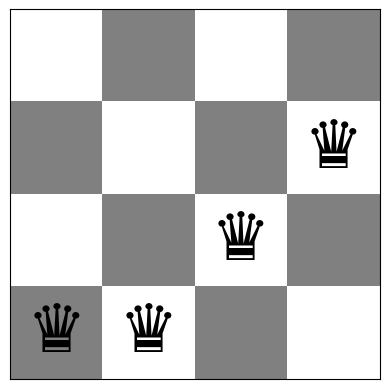

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [ ]:
# Tạo bàn cờ 4 x 4
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


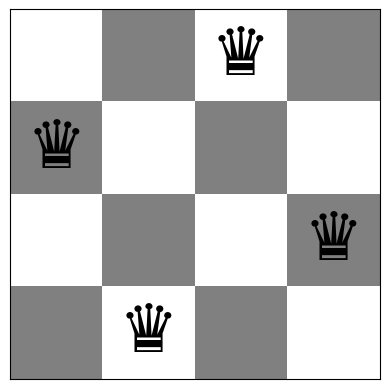

In [8]:
board = [1,3,0,2]
show_board(board)

In [ ]:
board4 = [1, 3, 0, 2]
show_board(board4)

print("Bàn cờ:", board4)
print("h(board) =", h(board4))
print("conflicts(board) =", conflicts(board4))

In [ ]:
# Tạo bàn cờ 8x8 ngẫu nhiên
board8_random = random_board(8)
show_board(board8_random)

print("Bàn cờ ngẫu nhiên:", board8_random)
print("h(board) =", h(board8_random))
print("conflicts(board) =", conflicts(board8_random))


# Một lời giải hợp lệ cho bài toán 8 quân hậu
board8_solution = [0, 4, 7, 5, 2, 6, 1, 3]
show_board(board8_solution)

print("Bàn cờ lời giải:", board8_solution)
print("h(board) =", h(board8_solution))
print("conflicts(board) =", conflicts(board8_solution))

In [ ]:
# Kiểm tra điều kiện h(board) = 0
def is_solution(board):
    n = len(board)

    # Kiểm tra giá trị hàng có hợp lệ không
    if any(row < 0 or row >= n for row in board):
        return False

    # Kiểm tra từng cặp quân hậu
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j]:
                return False

            if abs(board[i] - board[j]) == abs(i - j):
                return False

    return True

# Kiểm tra bàn cờ mẫu
boards = [
    [1, 3, 0, 2],
    [0, 4, 7, 5, 2, 6, 1, 3],
    random_board(4),
    random_board(8)
]

for board in boards:
    print("Bàn cờ:", board)
    print("h(board) =", h(board))
    print("Lời giải hợp lệ:", is_solution(board))
    print("Kiểm tra điều kiện:", (h(board) == 0) == is_solution(board))
    print("-" * 40)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

Board with 0 conflicts.


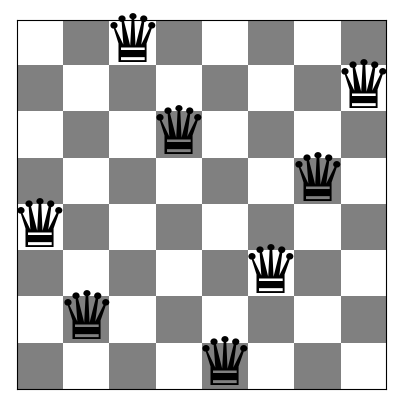

Bàn cờ cuối: [4 6 0 2 7 5 3 1]
Số xung đột cuối: 0
Số bước: 5
Số lần đánh giá: 336
Mắc kẹt tại cực tiểu cục bộ: False


In [9]:

def steepest_hill_climbing(board):
    board = np.array(board, dtype=int).copy()
    n = len(board)
    steps = 0
    evaluations = 0
    history = [conflicts(board)]

    while True:
        current_h = conflicts(board)
        best_board = None
        best_h = current_h
        # Duyệt tất cả nước đi lân cận
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue

                neighbor = board.copy()
                neighbor[col] = row
                neighbor_h = conflicts(neighbor)
                evaluations += 1
                # Chỉ giữ nước đi tốt hơn trạng thái hiện tại
                if neighbor_h < best_h:
                    best_h = neighbor_h
                    best_board = neighbor.copy()

        # Không còn nước đi cải thiện
        if best_board is None:
            break

        board = best_board
        steps += 1
        history.append(best_h)

    final_h = conflicts(board)

    return {
        "board": board,
        "conflicts": final_h,
        "steps": steps,
        "evaluations": evaluations,
        "local_optimum": final_h > 0,
        "plateau": final_h > 0,
        "history": history
    }

# Thử nghiệm với bàn cờ 8 quân hậu
result1 = steepest_hill_climbing(random_board(8))
show_board(result1["board"])
print("Bàn cờ cuối:", result1["board"])
print("Số xung đột cuối:", result1["conflicts"])
print("Số bước:", result1["steps"])
print("Số lần đánh giá:", result1["evaluations"])
print("Mắc kẹt tại cực tiểu cục bộ:", result1["local_optimum"])


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

Board with 1 conflicts.


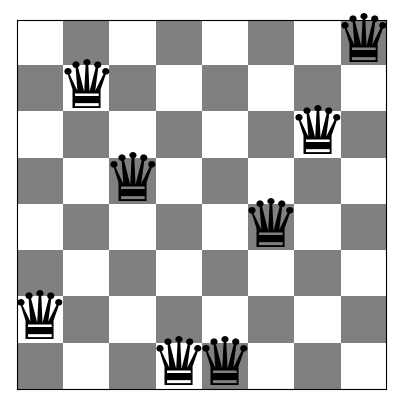

Bàn cờ cuối: [6 1 3 7 7 4 2 0]
Số xung đột cuối: 1
Số bước: 7
Số lần đánh giá: 448
Mắc kẹt tại cực tiểu cục bộ: True


In [10]:

def inefficient_stochastic_hill_climbing(board):
    board = np.array(board, dtype=int).copy()
    n = len(board)
    steps = 0
    evaluations = 0
    history = [conflicts(board)]

    while True:
        current_h = conflicts(board)
        improving_moves = []
        # Đánh giá toàn bộ nước đi lân cận
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue

                neighbor = board.copy()
                neighbor[col] = row
                neighbor_h = conflicts(neighbor)
                evaluations += 1
                if neighbor_h < current_h:
                    improving_moves.append((neighbor, neighbor_h))

        # Không có nước đi cải thiện thì dừng
        if len(improving_moves) == 0:
            break

        # Chọn ngẫu nhiên một nước đi cải thiện
        selected = np.random.randint(len(improving_moves))
        board = improving_moves[selected][0]
        steps += 1
        history.append(conflicts(board))

    final_h = conflicts(board)

    return {
        "board": board,
        "conflicts": final_h,
        "steps": steps,
        "evaluations": evaluations,
        "local_optimum": final_h > 0,
        "plateau": final_h > 0,
        "history": history
    }


# Thử nghiệm với bàn cờ 8 quân hậu
result2 = inefficient_stochastic_hill_climbing(random_board(8))
show_board(result2["board"])
print("Bàn cờ cuối:", result2["board"])
print("Số xung đột cuối:", result2["conflicts"])
print("Số bước:", result2["steps"])
print("Số lần đánh giá:", result2["evaluations"])
print("Mắc kẹt tại cực tiểu cục bộ:", result2["local_optimum"])


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

Board with 2 conflicts.


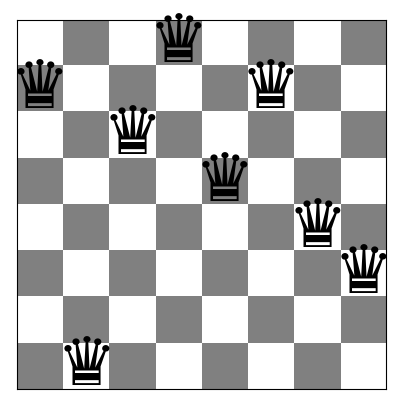

Bàn cờ cuối: [1 7 2 0 3 1 4 5]
Số xung đột cuối: 2
Số bước: 4
Số lần đánh giá: 577
Số lần thử không cải thiện liên tiếp: 560
Có khả năng mắc kẹt: True


In [13]:

def efficient_stochastic_hill_climbing(board, max_failures=None):
    board = np.array(board, dtype=int).copy()
    n = len(board)
    # Ngưỡng thử liên tiếp không cải thiện
    if max_failures is None:
        max_failures = 10 * n * (n - 1)
    steps = 0
    evaluations = 0
    failures = 0
    history = [conflicts(board)]

    while conflicts(board) > 0 and failures < max_failures:
        # Chọn ngẫu nhiên một cột
        col = np.random.randint(n)
        # Chọn một hàng khác hàng hiện tại
        possible_rows = [r for r in range(n) if r != board[col]]
        row = possible_rows[np.random.randint(len(possible_rows))]
        neighbor = board.copy()
        neighbor[col] = row
        neighbor_h = conflicts(neighbor)
        evaluations += 1
        # Chỉ chấp nhận nước đi cải thiện
        if neighbor_h < conflicts(board):
            board = neighbor
            steps += 1
            failures = 0
            history.append(neighbor_h)
        else:
            failures += 1

    final_h = conflicts(board)
    stopped_by_limit = failures >= max_failures and final_h > 0

    return {
        "board": board,
        "conflicts": final_h,
        "steps": steps,
        "evaluations": evaluations,
        "failures": failures,
        "local_optimum": stopped_by_limit,
        "plateau": stopped_by_limit,
        "history": history
    }

# Thử nghiệm với bàn cờ 8 quân hậu
result3 = efficient_stochastic_hill_climbing(random_board(8))
show_board(result3["board"])
print("Bàn cờ cuối:", result3["board"])
print("Số xung đột cuối:", result3["conflicts"])
print("Số bước:", result3["steps"])
print("Số lần đánh giá:", result3["evaluations"])
print("Số lần thử không cải thiện liên tiếp:", result3["failures"])
print("Có khả năng mắc kẹt:", result3["local_optimum"])


Ghi nhận và so sánh kết quả

In [20]:

def compare_hill_climbing(n, trials=100):
    algorithms = {
        "Steepest": steepest_hill_climbing,
        "Inefficient Stochastic": inefficient_stochastic_hill_climbing,
        "Efficient Stochastic": efficient_stochastic_hill_climbing
    }

    results = []

    for name, algorithm in algorithms.items():
        conflicts_list = []
        steps_list = []
        evaluations_list = []
        solved = 0
        stuck = 0

        for _ in range(trials):
            initial_board = random_board(n)
            result = algorithm(initial_board)

            conflicts_list.append(result["conflicts"])
            steps_list.append(result["steps"])
            evaluations_list.append(result["evaluations"])
            if result["conflicts"] == 0:
                solved += 1
            if result["local_optimum"]:
                stuck += 1

        results.append({
            "Algorithm": name,
            "n": n,
            "Trials": trials,
            "Avg final conflicts": np.mean(conflicts_list),
            "Avg steps": np.mean(steps_list),
            "Avg evaluations": np.mean(evaluations_list),
            "Success rate (%)": 100 * solved / trials,
            "Stuck rate (%)": 100 * stuck / trials
        })
    return results

# So sánh với n = 4
results_n4 = compare_hill_climbing(4, trials=100)

# So sánh với n = 8
results_n8 = compare_hill_climbing(8, trials=100)

# Hiển thị bảng kết quả
import pandas as pd

df = pd.DataFrame(results_n4 + results_n8)
display(df.round(2))


,Algorithm,n,Trials,Avg final conflicts,Avg steps,Avg evaluations,Success rate (%),Stuck rate (%)
0,Steepest,4,100,0.70,1.52,30.24,38.0,62.0
1,Inefficient Stochastic,4,100,0.76,1.86,34.32,35.0,65.0
2,Efficient Stochastic,4,100,0.80,1.97,95.06,31.0,69.0
3,Steepest,8,100,1.16,3.24,237.44,18.0,82.0
4,Inefficient Stochastic,8,100,1.18,5.09,341.04,16.0,84.0
5,Efficient Stochastic,8,100,1.41,4.47,562.13,11.0,89.0


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [25]:
import time
import math
import pandas as pd
from IPython.display import display

def random_restart(algorithm, n, max_restarts=100):
    start_time = time.perf_counter()

    best_board = None
    best_conflicts = float("inf")
    restarts_used = 0

    for restart in range(max_restarts):
        start_board = random_board(n)

        # Gọi thuật toán và nhận dictionary kết quả
        result_dict = algorithm(start_board)
        candidate = result_dict["board"]
        score = result_dict["conflicts"]
        restarts_used += 1

        if score < best_conflicts:
            best_conflicts = score
            best_board = candidate.copy()

        # Dừng sớm nếu tìm thấy lời giải tối ưu
        if best_conflicts == 0:
            break

    elapsed = time.perf_counter() - start_time

    return {
        "Board size": n,
        "Restarts used": restarts_used,
        "Best conflicts": best_conflicts,
        "Optimal": best_conflicts == 0,
        "Runtime (ms)": elapsed * 1000,
        "Best board": best_board.tolist()
    }

hc_algorithms = {
    "Steepest asc. HC": steepest_hill_climbing,
    "Ineff. Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing
}

restart_results = []

# Thử nghiệm với bàn cờ n=8
for name, algorithm in hc_algorithms.items():
    result = random_restart(algorithm, n=8, max_restarts=100)
    result["Algorithm"] = name
    restart_results.append(result)

display(pd.DataFrame(restart_results))

,Board size,Restarts used,Best conflicts,Optimal,Runtime (ms),Best board,Algorithm
0,8,12,0,True,58.460100,"[5, 2, 0, 7, 4, 1, 3, 6]",Steepest asc. HC
1,8,7,0,True,39.615293,"[6, 2, 0, 5, 7, 4, 1, 3]",Ineff. Stochastic HC
2,8,3,0,True,77.614426,"[4, 6, 3, 0, 2, 7, 5, 1]",Efficient Stochastic HC


In [26]:
# Task 4 — Thống kê số lần thành công của Random Restart
def summarize_random_restarts(
    name, algorithm, n=8, trials=100, max_restarts=100
):
    results = []

    # Repeat the complete random-restart experiment.
    for _ in range(trials):
        result = random_restart(
            algorithm,
            n=n,
            max_restarts=max_restarts
        )
        results.append(result)

    df = pd.DataFrame(results)

    success_count = int(df["Optimal"].sum())

    return {
        "Algorithm": name,
        "Board size": n,
        "Experiments": trials,
        "Successful experiments (h=0)": success_count,
        "Success rate (%)": success_count / trials * 100,
        "Average restarts": df["Restarts used"].mean(),
        "Average best h": df["Best conflicts"].mean(),
        "Best h observed": df["Best conflicts"].min(),
        "Average runtime (ms)": df["Runtime (ms)"].mean(),
        "Total runtime (s)": df["Runtime (ms)"].sum() / 1000
    }


restart_summary = []

for name, algorithm in hc_algorithms.items():
    summary = summarize_random_restarts(
        name,
        algorithm,
        n=8,
        trials=100,
        max_restarts=100
    )
    restart_summary.append(summary)

restart_table = pd.DataFrame(restart_summary)
display(restart_table.round(3))

,Algorithm,Board size,Experiments,Successful experiments (h=0),Success rate (%),Average restarts,Average best h,Best h observed,Average runtime (ms),Total runtime (s)
0,Steepest asc. HC,8,100,100,100.0,6.77,0.0,0,23.440,2.344
1,Ineff. Stochastic HC,8,100,100,100.0,6.99,0.0,0,35.106,3.511
2,Efficient Stochastic HC,8,100,100,100.0,6.93,0.0,0,265.255,26.526


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [27]:
# Task 5: Simulated Annealing [10 Points]
# Code and description go here
def temperature_at(
    iteration, T0, schedule, alpha, max_iter, Tmin=1e-3
):
    """Calculate the temperature at a given iteration."""

    if schedule == "geometric":
        return T0 * (alpha ** iteration)

    if schedule == "linear":
        return max(
            Tmin,
            T0 * (1 - iteration / max_iter)
        )

    if schedule == "logarithmic":
        return T0 / math.log(iteration + math.e)

    raise ValueError("Unknown annealing schedule")


def simulated_annealing(
    start_board,
    T0=2.0,
    alpha=0.995,
    max_iter=3000,
    schedule="geometric",
    Tmin=1e-3
):
    """Solve N-Queens using simulated annealing."""

    board = np.array(start_board, dtype=int).copy()
    current = conflicts(board)

    # Preserve the best solution found throughout the search.
    best_board = board.copy()
    best_value = current

    current_history = [current]
    best_history = [best_value]

    for iteration in range(max_iter):
        if best_value == 0:
            break

        temperature = temperature_at(
            iteration, T0, schedule, alpha, max_iter, Tmin
        )

        candidate = random_neighbor(board)
        candidate_value = conflicts(candidate)
        delta = candidate_value - current

        # Always accept improving or equal-quality moves.
        # Accept worse moves probabilistically.
        if (
            delta <= 0
            or (
                temperature > 0
                and np.random.random()
                < math.exp(-delta / temperature)
            )
        ):
            board = candidate
            current = candidate_value

        # Update the best solution found so far.
        if current < best_value:
            best_board = board.copy()
            best_value = current

        current_history.append(current)
        best_history.append(best_value)

    return best_board, current_history, best_history

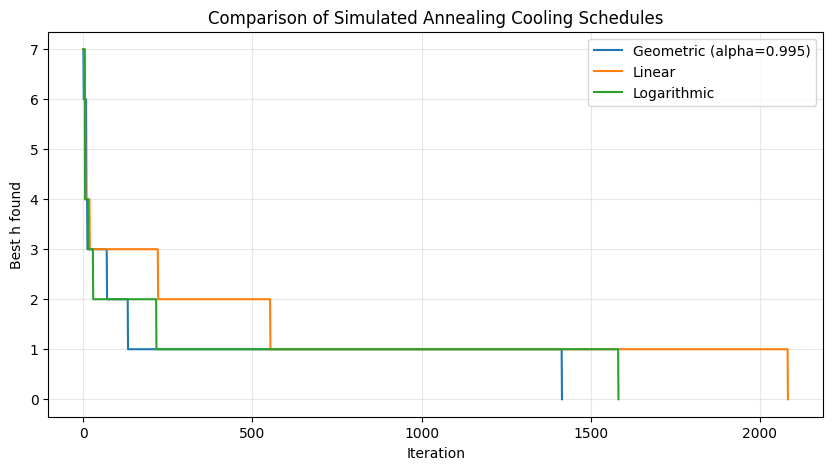

,Cooling schedule,Best h,Success (h=0),Iterations
0,Geometric (alpha=0.995),0,True,1415
1,Linear,0,True,2083
2,Logarithmic,0,True,1582


In [28]:
# Task 5 — Thử các lịch làm nguội khác nhau
# Geometric, Linear và Logarithmic.
np.random.seed(2026)

n = 8
start_board = random_board(n)

T0 = 2.0
max_iter = 3000

cooling_schedules = [
    ("Geometric (alpha=0.995)", "geometric", 0.995),
    ("Linear", "linear", 0.995),
    ("Logarithmic", "logarithmic", 0.995)
]

schedule_results = []

plt.figure(figsize=(10, 5))

for name, schedule, alpha in cooling_schedules:
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board.copy(),
            T0=T0,
            alpha=alpha,
            max_iter=max_iter,
            schedule=schedule
        )
    )

    best_h = conflicts(best_board)

    schedule_results.append({
        "Cooling schedule": name,
        "Best h": best_h,
        "Success (h=0)": best_h == 0,
        "Iterations": len(current_history) - 1
    })

    plt.plot(best_history, label=name)

plt.xlabel("Iteration")
plt.ylabel("Best h found")
plt.title("Comparison of Simulated Annealing Cooling Schedules")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

display(pd.DataFrame(schedule_results))

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [31]:
# Task 6
# Code
def sa_benchmark_runner(start_board):
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board,
            T0=2.0,
            alpha=0.995,
            max_iter=3000,
            schedule="geometric"
        )
    )
    # Return only the final board and best history to match other algorithms' output format
    return best_board, best_history


comparison_algorithms = {
    "Steepest asc. HC": steepest_hill_climbing,
    "Ineff. Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing,
    "Simulated Annealing": sa_benchmark_runner
}

comparison_rows = []

for n in [4, 8]:
    # Generate 100 different initial boards.
    initial_boards = [random_board(n) for _ in range(100)]

    for name, algorithm in comparison_algorithms.items():
        run_times = []
        final_conflict_counts = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            # We support both dict return (for our HC algorithms) and tuple return (for SA)
            res = algorithm(initial_board.copy())
            if isinstance(res, dict):
                final_board = res["board"]
            else:
                final_board = res[0]

            elapsed = time.perf_counter() - start_time

            run_times.append(elapsed)
            final_conflict_counts.append(
                conflicts(final_board)
            )

        run_times = np.array(run_times)
        final_conflict_counts = np.array(
            final_conflict_counts
        )

        comparison_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Avg. Run time (ms)": (
                np.mean(run_times) * 1000
            ),
            "Avg. number of conflicts": np.mean(
                final_conflict_counts
            ),
            "% Optimal": (
                np.mean(final_conflict_counts == 0) * 100
            )
        })

comparison_table = pd.DataFrame(comparison_rows)

display(
    comparison_table.round(3)
)

,Algorithm,Board size,Avg. Run time (ms),Avg. number of conflicts,% Optimal
0,Steepest asc. HC,4,0.630,0.62,44.0
1,Ineff. Stochastic HC,4,0.713,0.79,32.0
2,Efficient Stochastic HC,4,5.906,0.79,36.0
3,Simulated Annealing,4,1.458,0.00,100.0
4,Steepest asc. HC,8,4.131,1.22,15.0
5,Ineff. Stochastic HC,8,11.045,1.20,18.0
6,Efficient Stochastic HC,8,24.967,1.23,22.0
7,Simulated Annealing,8,21.336,0.03,97.0


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [34]:
import time
import numpy as np
import pandas as pd
from IPython.display import display

def generate_unique_initial_boards(n, count=100):
    """Generate distinct board vectors for each experiment."""
    if count > n ** n:
        raise ValueError("Too many distinct initial boards requested.")

    boards = []
    seen = set()

    while len(boards) < count:
        board = np.random.randint(0, n, size=n)
        key = tuple(board.tolist())

        if key not in seen:
            seen.add(key)
            boards.append(board)

    return boards


def sa_benchmark_runner(start_board):
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board,
            T0=2.0,
            alpha=0.995,
            max_iter=3000,
            schedule="geometric"
        )
    )
    return best_board, best_history


comparison_algorithms = {
    "Steepest asc. HC": steepest_hill_climbing,
    "Ineff. Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing,
    "Simulated Annealing": sa_benchmark_runner
}

np.random.seed(1234)

comparison_rows = []

for n in [4, 8]:
    # Use 100 distinct initial boards for each board size.
    initial_boards = generate_unique_initial_boards(n, 100)

    for name, algorithm in comparison_algorithms.items():
        run_times = []
        final_h_values = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            # Đồng nhất kiểu trả về của các thuật toán (dict vs tuple)
            res = algorithm(initial_board.copy())
            if isinstance(res, dict):
                final_board = res["board"]
            else:
                final_board = res[0]

            elapsed = time.perf_counter() - start_time

            run_times.append(elapsed)
            final_h_values.append(conflicts(final_board))

        final_h_values = np.array(final_h_values)
        success_count = int(np.sum(final_h_values == 0))

        comparison_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Runs": len(final_h_values),
            "Avg. runtime (ms)": np.mean(run_times) * 1000,
            "Avg. final h": np.mean(final_h_values),
            "Best h observed": np.min(final_h_values),
            "Successful runs (h=0)": success_count,
            "Success rate (%)": success_count / len(final_h_values) * 100
        })

comparison_table = pd.DataFrame(comparison_rows)

display(comparison_table.round(3))

,Algorithm,Board size,Runs,Avg. runtime (ms),Avg. final h,Best h observed,Successful runs (h=0),Success rate (%)
0,Steepest asc. HC,4,100,0.323,0.58,0,46,46.0
1,Ineff. Stochastic HC,4,100,0.361,0.82,0,34,34.0
2,Efficient Stochastic HC,4,100,3.039,0.74,0,39,39.0
3,Simulated Annealing,4,100,1.269,0.00,0,100,100.0
4,Steepest asc. HC,8,100,5.129,1.32,0,17,17.0
5,Ineff. Stochastic HC,8,100,10.078,1.35,0,16,16.0
6,Efficient Stochastic HC,8,100,47.711,1.24,0,14,14.0
7,Simulated Annealing,8,100,22.716,0.04,0,96,96.0


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

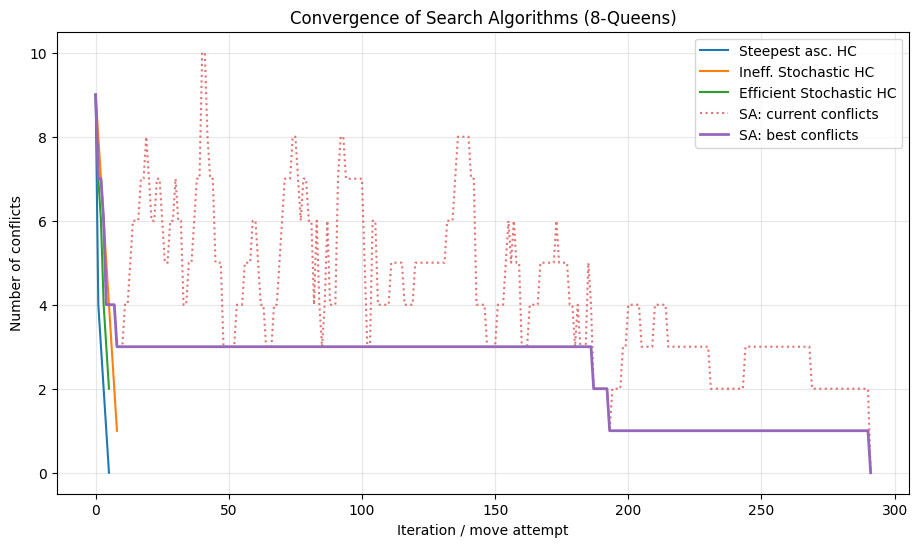

In [36]:
# Code and description go here
import numpy as np
import matplotlib.pyplot as plt

# Định nghĩa hàm láng giềng ngẫu nhiên vì Simulated Annealing cần dùng
def random_neighbor(board):
    neighbor = board.copy()
    n = len(board)
    col = np.random.randint(n)
    possible_rows = [r for r in range(n) if r != board[col]]
    row = np.random.choice(possible_rows)
    neighbor[col] = row
    return neighbor

n = 8
start_board = random_board(n)

plt.figure(figsize=(11, 6))

# Vẽ biểu đồ cho 3 biến thể Hill Climbing
for name, algorithm in hc_algorithms.items():
    res = algorithm(start_board.copy())
    if isinstance(res, dict):
        final_board = res["board"]
        history = res["history"]
    else:
        final_board, history = res

    plt.plot(
        range(len(history)),
        history,
        label=name
    )

# Vẽ biểu đồ Simulated Annealing (cả trạng thái hiện tại và tốt nhất)
_, current_history, best_history = simulated_annealing(
    start_board.copy(),
    T0=2.0,
    alpha=0.995,
    max_iter=3000,
    schedule="geometric"
)

plt.plot(
    current_history,
    linestyle=":",
    alpha=0.65,
    label="SA: current conflicts"
)

plt.plot(
    best_history,
    linewidth=2,
    label="SA: best conflicts"
)

plt.xlabel("Iteration / move attempt")
plt.ylabel("Number of conflicts")
plt.title("Convergence of Search Algorithms (8-Queens)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [39]:
# Problem Size Scalability
# Code and description go here
scaling_algorithms = {
    "Steepest asc. HC": steepest_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing
}

board_sizes = [4, 8, 12, 16, 20]
repeats = 30

scaling_rows = []

for n in board_sizes:
    # Use independent random starting boards.
    initial_boards = [
        random_board(n) for _ in range(repeats)
    ]

    for name, algorithm in scaling_algorithms.items():
        run_times = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            res = algorithm(initial_board.copy())
            if isinstance(res, dict):
                final_board = res["board"]
                history = res["history"]
            else:
                final_board, history = res

            elapsed = time.perf_counter() - start_time
            run_times.append(elapsed)

        scaling_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Avg. runtime (s)": np.mean(run_times)
        })

scaling_table = pd.DataFrame(scaling_rows)
display(scaling_table.round(6))

,Algorithm,Board size,Avg. runtime (s)
0,Steepest asc. HC,4,0.000289
1,Efficient Stochastic HC,4,0.002587
2,Steepest asc. HC,8,0.003551
3,Efficient Stochastic HC,8,0.027113
4,Steepest asc. HC,12,0.015750
5,Efficient Stochastic HC,12,0.102316
6,Steepest asc. HC,16,0.049526
7,Efficient Stochastic HC,16,0.349680
8,Steepest asc. HC,20,0.112498
9,Efficient Stochastic HC,20,0.570261


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem

Steepest asc. HC: estimated exponent p = 3.71; empirical runtime approximately proportional to n^3.71 over the tested range.
Efficient Stochastic HC: estimated exponent p = 3.42; empirical runtime approximately proportional to n^3.42 over the tested range.


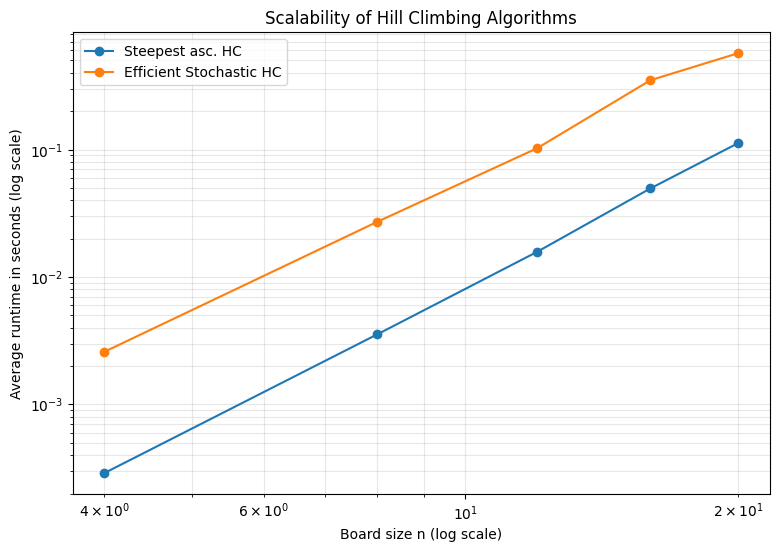

In [40]:
# Code and description go here
plt.figure(figsize=(9, 6))

for name in scaling_algorithms:
    subset = scaling_table[
        scaling_table["Algorithm"] == name
    ].sort_values("Board size")

    x = subset["Board size"].to_numpy(dtype=float)
    y = subset["Avg. runtime (s)"].to_numpy(dtype=float)

    plt.loglog(
        x, y,
        marker="o",
        label=name
    )

    # Fit log(time) = p * log(n) + intercept.
    p, intercept = np.polyfit(
        np.log(x), np.log(y), 1
    )

    print(
        f"{name}: estimated exponent p = {p:.2f}; "
        f"empirical runtime approximately proportional "
        f"to n^{p:.2f} over the tested range."
    )

plt.xlabel("Board size n (log scale)")
plt.ylabel("Average runtime in seconds (log scale)")
plt.title("Scalability of Hill Climbing Algorithms")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()